# Data Visualisation: Environmental Trends and Risks

This notebook uses `global_climate_impact_1990_2025.csv` to communicate air-quality and climate indicators through clear, unit-labelled charts. The visualisations focus on long-term particulate trends, measurement coverage, recent geographic differences, emissions and temperature trends, and the relationship between PM2.5 and respiratory disease rates.

## How to interpret the charts
- Annual country averages are **equally weighted across available countries**, not weighted by population.
- Missing values are omitted from each chart and summary; measurement coverage is shown where relevant.
- Dashed PM2.5 (5 µg/m³) and PM10 (15 µg/m³) reference lines show the WHO 2021 annual guideline values. They are health-based guidelines, not a regulatory determination.
- CO₂ emissions totals and ambient pollutant concentrations are different measures.
- The respiratory-disease chart is descriptive; association does not establish causation or individual exposure.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CSV_NAME = "global_climate_impact_1990_2025.csv"
data_path = next(
    (parent / CSV_NAME for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / CSV_NAME).is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        f"Could not find {CSV_NAME!r} in the current directory or its parents."
    )

df = pd.read_csv(data_path)
required_columns = {
    "Country", "Continent", "Year", "PM2_5_Annual_Mean_ug_m3",
    "PM10_Annual_Mean_ug_m3", "CO2_Emissions_Total_Mt",
    "Temperature_Anomaly_C", "Respiratory_Disease_Rate_Per100k",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")

df["Year"] = pd.to_numeric(df["Year"], errors="raise").astype(int)
latest_year = int(df["Year"].max())
print(
    f"Loaded {len(df):,} country-year observations for "
    f"{df['Country'].nunique():,} countries ({df['Year'].min()}–{latest_year})."
)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"PM2.5": "#b23a48", "PM10": "#28666e", "CO2": "#4c956c", "climate": "#59656f"}
PM25_GUIDELINE = 5.0
PM10_GUIDELINE = 15.0

Loaded 6,948 country-year observations for 193 countries (1990–2025).


## 1. Particulate pollution trends and reporting coverage

The first figure pairs the annual mean concentration with the number of countries that reported a value. This helps distinguish changes in the measured mean from changes in coverage.

In [4]:
annual_pm = df.groupby("Year").agg(
    PM2_5_mean=("PM2_5_Annual_Mean_ug_m3", "mean"),
    PM2_5_n=("PM2_5_Annual_Mean_ug_m3", "count"),
    PM10_mean=("PM10_Annual_Mean_ug_m3", "mean"),
    PM10_n=("PM10_Annual_Mean_ug_m3", "count"),
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
axes[0].plot(annual_pm.index, annual_pm["PM2_5_mean"], color=COLORS["PM2.5"],
             linewidth=2, label="PM2.5")
axes[0].plot(annual_pm.index, annual_pm["PM10_mean"], color=COLORS["PM10"],
             linewidth=2, label="PM10")
axes[0].axhline(PM25_GUIDELINE, color=COLORS["PM2.5"], linestyle="--", alpha=0.7,
                label="WHO PM2.5 guideline: 5 µg/m³")
axes[0].axhline(PM10_GUIDELINE, color=COLORS["PM10"], linestyle="--", alpha=0.7,
                label="WHO PM10 guideline: 15 µg/m³")
axes[0].set(title="Annual mean particulate concentrations across reporting countries",
            ylabel="Concentration (µg/m³)")
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(annual_pm.index, annual_pm["PM2_5_n"], color=COLORS["PM2.5"],
             label="PM2.5 reporting countries")
axes[1].plot(annual_pm.index, annual_pm["PM10_n"], color=COLORS["PM10"],
             label="PM10 reporting countries")
axes[1].set(xlabel="Year", ylabel="Countries with measurements",
            title="Measurement coverage")
axes[1].legend(frameon=False, ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("Particulate matter: trend and coverage", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

display(annual_pm.loc[[annual_pm.index.min(), annual_pm.index.max()]].round(2))

<Figure size 1200x900 with 2 Axes>

,PM2_5_mean,PM2_5_n,PM10_mean,PM10_n
Year,,,,
1990,24.70,124,39.34,113
2025,19.82,192,30.62,191


## 2. Recent PM2.5 differences by continent and country

Use the latest year in the file rather than assuming a fixed end year. The continent chart shows both its country-average level and the number of reporting countries; the country chart highlights the highest observed readings.

## 3. Climate and emissions signals

Temperature anomaly and reported CO₂ emissions have different units and meanings, so they are plotted in separate panels. The emissions panel shows reporting counts because missing country totals can influence the sum.

## 4. Geographic hotspot map by continent and year

This heatmap shows mean PM2.5 by continent and year. It is a compact way to compare broad regional patterns across time; cells with fewer reporting countries may be less representative.

## 5. Pollution and respiratory disease: descriptive association

A scatter plot reveals the distribution and possible association without hiding outliers behind a single summary statistic. The correlation is descriptive and may reflect shared trends or confounders.

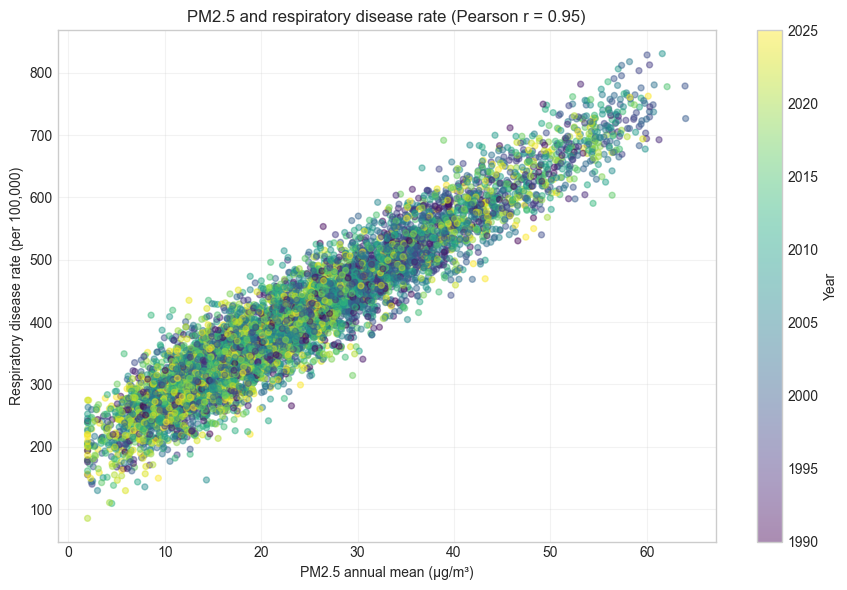

Paired country-year observations: 6,430


In [5]:
relationship = df.loc[
    :,
    [
        "PM2_5_Annual_Mean_ug_m3",
        "Respiratory_Disease_Rate_Per100k",
        "Year",
    ],
].apply(pd.to_numeric, errors="coerce").dropna()

if len(relationship) < 2:
    print("Not enough paired measurements to visualize the relationship.")
else:
    pm25 = relationship["PM2_5_Annual_Mean_ug_m3"]
    respiratory_rate = relationship["Respiratory_Disease_Rate_Per100k"]
    correlation = pm25.corr(respiratory_rate)
    correlation_label = f"{correlation:.2f}" if np.isfinite(correlation) else "undefined"

    fig, ax = plt.subplots(figsize=(9, 6))
    points = ax.scatter(
        pm25,
        respiratory_rate,
        c=relationship["Year"],
        cmap="viridis",
        alpha=0.45,
        s=18,
    )
    fig.colorbar(points, ax=ax, label="Year")
    ax.set(
        title=f"PM2.5 and respiratory disease rate (Pearson r = {correlation_label})",
        xlabel="PM2.5 annual mean (µg/m³)",
        ylabel="Respiratory disease rate (per 100,000)",
    )
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    print(f"Paired country-year observations: {len(relationship):,}")